# Human Activity Recognition — Model Comparison

This notebook compares **already-trained model checkpoints** on one consistent, participant-separated validation split. It does **not** train models, overwrite model checkpoints, or evaluate the official test set.

## Models included
1. Baseline CNN-LSTM
2. Class-weighted CNN-LSTM
3. CNN-only
4. Targeted class-weighted CNN
5. Verified candidate CNN (packaged copy)

The targeted CNN and verified candidate may be copies of the same experiment. They are listed separately to verify that, but should not be described as independent architectures unless their checkpoints differ.

**Important:** this validation split has already been used for model development/model selection, so these results are validation results, not an untouched final-test estimate.

## 1. Mount Google Drive and configure paths

Run this notebook in Google Colab. Check the project folder name if yours differs. This notebook loads the existing preprocessed dataset and saved checkpoints only.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from IPython.display import display

warnings.filterwarnings("ignore")

SEED = 42
tf.keras.utils.set_random_seed(SEED)

PROJECT_DIR = Path("/content/drive/MyDrive/Human_Activity_Recognition")
DATA_FILE = PROJECT_DIR / "01_Dataset_Preprocessing/processed_data/har_processed_data.npz"
OUTPUT_DIR = PROJECT_DIR / "03_Final_Model/model_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Project folder exists:", PROJECT_DIR.exists())
print("Dataset file:", DATA_FILE)
print("Comparison outputs:", OUTPUT_DIR)

Mounted at /content/drive
TensorFlow: 2.21.0
Project folder exists: True
Dataset file: /content/drive/MyDrive/Human_Activity_Recognition/01_Dataset_Preprocessing/processed_data/har_processed_data.npz
Comparison outputs: /content/drive/MyDrive/Human_Activity_Recognition/03_Final_Model/model_comparison


## 2. Load and verify the preprocessed dataset

The saved signals are already preprocessed/normalized. Do not normalize them again here.

In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Processed dataset not found: {DATA_FILE}\n"
        "Confirm the Google Drive project folder and dataset location."
    )

data = np.load(DATA_FILE, allow_pickle=False)

required_arrays = {
    "X_train", "y_train", "subject_train",
    "activity_names", "channel_names"
}
missing = required_arrays.difference(data.files)
if missing:
    raise KeyError(f"Dataset is missing required arrays: {sorted(missing)}")

X_train = data["X_train"]
y_train = data["y_train"].astype(int)
subject_train = data["subject_train"]
activity_names = data["activity_names"].tolist()
channel_names = data["channel_names"].tolist()

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("Channels:", channel_names)
print("Activities:", activity_names)
print("All signal values finite:", bool(np.isfinite(X_train).all()))
print("Missing values in signals:", int(np.isnan(X_train).sum()))

assert X_train.ndim == 3 and X_train.shape[1:] == (128, 6), (
    f"Expected X_train shape (N, 128, 6); got {X_train.shape}"
)
assert len(activity_names) == 6
assert len(channel_names) == 6
assert np.isfinite(X_train).all(), "Signal array contains non-finite values."
assert set(np.unique(y_train)).issubset(set(range(len(activity_names))))

X_train: (7352, 128, 6) float32
y_train: (7352,) int64
Channels: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z']
Activities: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
All signal values finite: True
Missing values in signals: 0


## 3. Recreate the participant-separated validation split

This reproduces the split used in the training notebook (`test_size=0.20`, `random_state=42`). It checks that participants in the fitting subset and validation subset do not overlap.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
fit_idx, val_idx = next(
    splitter.split(X_train, y_train, groups=subject_train)
)

X_fit, X_val = X_train[fit_idx], X_train[val_idx]
y_fit, y_val = y_train[fit_idx], y_train[val_idx]

fit_subjects = set(np.asarray(subject_train[fit_idx]).tolist())
val_subjects = set(np.asarray(subject_train[val_idx]).tolist())

assert fit_subjects.isdisjoint(val_subjects), "Participant leakage detected!"

print("Fit subset:", X_fit.shape, y_fit.shape)
print("Validation subset:", X_val.shape, y_val.shape)
print("Fit participants:", sorted(fit_subjects))
print("Validation participants:", sorted(val_subjects))
print("Participant overlap:", fit_subjects.intersection(val_subjects))
display(
    pd.DataFrame({
        "Activity": activity_names,
        "Fit windows": np.bincount(y_fit, minlength=len(activity_names)),
        "Validation windows": np.bincount(y_val, minlength=len(activity_names))
    })
)

Fit subset: (5551, 128, 6) (5551,)
Validation subset: (1801, 128, 6) (1801,)
Fit participants: [5, 6, 7, 8, 11, 14, 16, 17, 19, 21, 22, 23, 26, 28, 29, 30]
Validation participants: [1, 3, 15, 25, 27]
Participant overlap: set()


,Activity,Fit windows,Validation windows
0,WALKING,888,338
1,WALKING_UPSTAIRS,797,276
2,WALKING_DOWNSTAIRS,744,242
3,SITTING,993,293
4,STANDING,1053,321
5,LAYING,1076,331


## 4. Find and load all saved model checkpoints

Each model is loaded independently from its saved checkpoint. Missing checkpoints are reported and skipped rather than crashing the entire comparison. No model is saved over or modified.

In [4]:
MODEL_PATHS = {
    "Baseline CNN-LSTM": (
        PROJECT_DIR / "02_Model_Training/outputs/best_cnn_lstm.keras"
    ),
    "Class-weighted CNN-LSTM": (
        PROJECT_DIR / "02_Model_Training/outputs/class_weighted/best_weighted_cnn_lstm.keras"
    ),
    "CNN-only": (
        PROJECT_DIR / "02_Model_Training/outputs/cnn_only/best_cnn_only.keras"
    ),
    "Targeted class-weighted CNN": (
        PROJECT_DIR / "02_Model_Training/outputs/targeted_sitting_experiment/best_targeted_cnn.keras"
    ),
    "Verified candidate CNN": (
        PROJECT_DIR / "03_Final_Model/final_model/har_cnn_model_verified_candidate.keras"
    ),
}

checkpoint_inventory = []
loaded_models = {}

for model_name, path in MODEL_PATHS.items():
    exists = path.exists()
    checkpoint_inventory.append({
        "Model": model_name,
        "Checkpoint exists": exists,
        "Path": str(path)
    })

    if not exists:
        print(f"NOT FOUND — {model_name}: {path}")
        continue

    try:
        loaded = tf.keras.models.load_model(path, compile=False)
        if tuple(loaded.input_shape[1:]) != tuple(X_val.shape[1:]):
            print(
                f"SKIPPED — {model_name}: input shape {loaded.input_shape}; "
                f"expected (None, {X_val.shape[1]}, {X_val.shape[2]})"
            )
            continue
        if loaded.output_shape[-1] != len(activity_names):
            print(
                f"SKIPPED — {model_name}: output classes {loaded.output_shape[-1]}; "
                f"expected {len(activity_names)}"
            )
            continue

        loaded_models[model_name] = loaded
        print(f"LOADED — {model_name} | input={loaded.input_shape} | output={loaded.output_shape}")
    except Exception as exc:
        print(f"FAILED TO LOAD — {model_name}: {type(exc).__name__}: {exc}")

inventory_df = pd.DataFrame(checkpoint_inventory)
display(inventory_df)

if not loaded_models:
    raise RuntimeError(
        "No compatible model checkpoints were loaded. Check the paths above."
    )

print(f"\nSuccessfully loaded {len(loaded_models)} of {len(MODEL_PATHS)} configured checkpoints.")

LOADED — Baseline CNN-LSTM | input=(None, 128, 6) | output=(None, 6)
LOADED — Class-weighted CNN-LSTM | input=(None, 128, 6) | output=(None, 6)
LOADED — CNN-only | input=(None, 128, 6) | output=(None, 6)
LOADED — Targeted class-weighted CNN | input=(None, 128, 6) | output=(None, 6)
LOADED — Verified candidate CNN | input=(None, 128, 6) | output=(None, 6)


,Model,Checkpoint exists,Path
0,Baseline CNN-LSTM,True,/content/drive/MyDrive/Human_Activity_Recognit...
1,Class-weighted CNN-LSTM,True,/content/drive/MyDrive/Human_Activity_Recognit...
2,CNN-only,True,/content/drive/MyDrive/Human_Activity_Recognit...
3,Targeted class-weighted CNN,True,/content/drive/MyDrive/Human_Activity_Recognit...
4,Verified candidate CNN,True,/content/drive/MyDrive/Human_Activity_Recognit...



Successfully loaded 5 of 5 configured checkpoints.


## 5. Evaluate all loaded models on the same validation samples

Metrics include accuracy, macro precision/recall/F1, weighted F1, and approximate prediction time per window. Inference timing is approximate and depends on the Colab runtime; it is not a hardware-independent benchmark.

In [5]:
all_predictions = {}
all_probabilities = {}
summary_rows = []
per_class_rows = []
classification_reports = {}

for model_name, loaded in loaded_models.items():
    # Warm-up call to reduce first-call overhead in timing.
    _ = loaded.predict(X_val[:min(8, len(X_val))], verbose=0)

    start = time.perf_counter()
    probs = loaded.predict(X_val, batch_size=128, verbose=0)
    elapsed = time.perf_counter() - start

    preds = np.argmax(probs, axis=1)
    truth = np.asarray(y_val).astype(int)

    all_predictions[model_name] = preds
    all_probabilities[model_name] = probs

    summary_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(truth, preds),
        "Macro precision": precision_score(truth, preds, average="macro", zero_division=0),
        "Macro recall": recall_score(truth, preds, average="macro", zero_division=0),
        "Macro F1": f1_score(truth, preds, average="macro", zero_division=0),
        "Weighted F1": f1_score(truth, preds, average="weighted", zero_division=0),
        "Total prediction time (s)": elapsed,
        "Time per window (ms)": 1000 * elapsed / len(X_val),
        "Validation windows": len(X_val)
    })

    report = classification_report(
        truth,
        preds,
        labels=np.arange(len(activity_names)),
        target_names=activity_names,
        output_dict=True,
        zero_division=0
    )
    classification_reports[model_name] = report

    for activity in activity_names:
        per_class_rows.append({
            "Model": model_name,
            "Activity": activity,
            "Precision": report[activity]["precision"],
            "Recall": report[activity]["recall"],
            "F1": report[activity]["f1-score"],
            "Support": report[activity]["support"]
        })

summary_df = pd.DataFrame(summary_rows).sort_values(
    ["Macro F1", "Accuracy"], ascending=False
).reset_index(drop=True)

per_class_df = pd.DataFrame(per_class_rows)

display(summary_df.style.format({
    "Accuracy": "{:.4f}",
    "Macro precision": "{:.4f}",
    "Macro recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}",
    "Total prediction time (s)": "{:.3f}",
    "Time per window (ms)": "{:.4f}"
}))

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Total prediction time (s),Time per window (ms),Validation windows
0,Targeted class-weighted CNN,0.8778,0.8834,0.8823,0.8814,0.8765,0.626,0.3473,1801
1,Verified candidate CNN,0.8778,0.8834,0.8823,0.8814,0.8765,0.685,0.3803,1801
2,CNN-only,0.8201,0.8484,0.8234,0.8140,0.8088,0.634,0.3518,1801
3,Baseline CNN-LSTM,0.7929,0.8127,0.7947,0.7888,0.7854,1.354,0.7517,1801
4,Class-weighted CNN-LSTM,0.7529,0.7407,0.7550,0.7281,0.7235,0.982,0.5452,1801


## 6. Compare overall metrics visually

Macro F1 is highlighted as a useful comparison metric because it gives each activity class equal weight. Accuracy is also shown; the preferred model should consider both overall performance and per-activity errors.

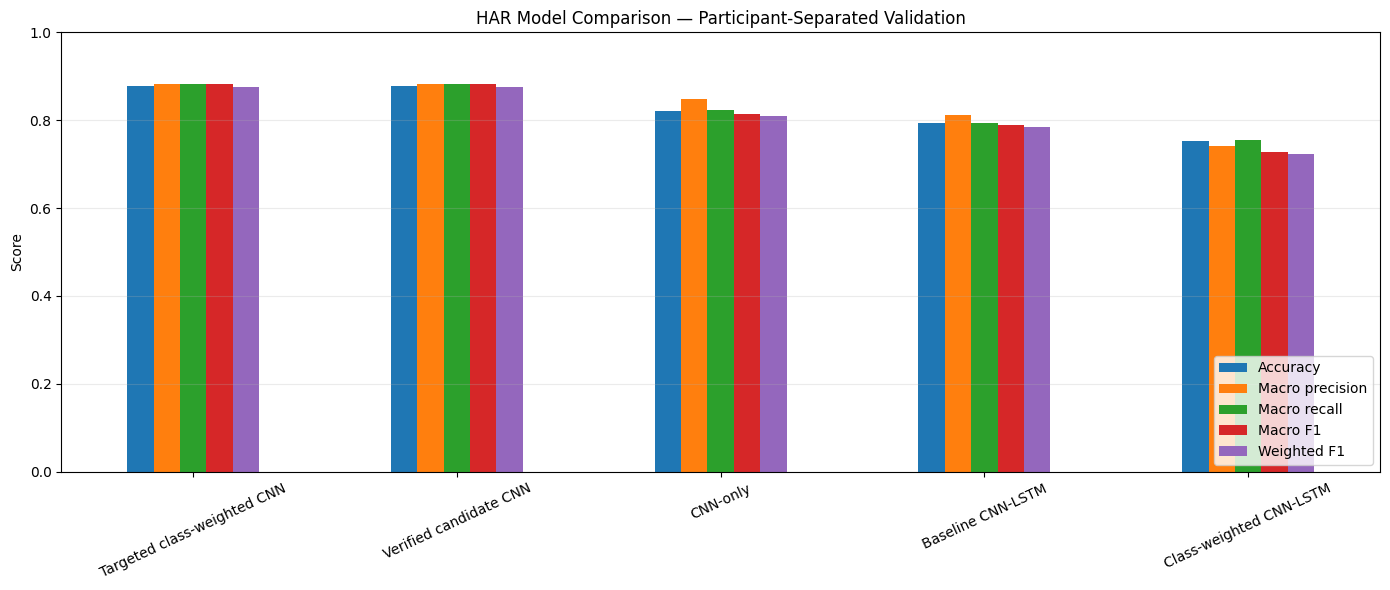

Highest validation Macro F1:


,Model,Macro F1,Accuracy
0,Targeted class-weighted CNN,0.881358,0.877846


Highest validation accuracy:


,Model,Accuracy,Macro F1
0,Targeted class-weighted CNN,0.877846,0.881358


In [6]:
metric_columns = [
    "Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"
]
ax = summary_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(14, 6), ylim=(0, 1), rot=25
)
ax.set_title("HAR Model Comparison — Participant-Separated Validation")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Highest validation Macro F1:")
display(summary_df.loc[[summary_df["Macro F1"].idxmax()], ["Model", "Macro F1", "Accuracy"]])

print("Highest validation accuracy:")
display(summary_df.loc[[summary_df["Accuracy"].idxmax()], ["Model", "Accuracy", "Macro F1"]])

## 7. Compare per-activity F1 scores

This helps identify whether a model's overall score hides weak performance on SITTING, STANDING, or LAYING.

Model,Baseline CNN-LSTM,CNN-only,Class-weighted CNN-LSTM,Targeted class-weighted CNN,Verified candidate CNN
Activity,,,,,
WALKING,0.975,0.990,0.981,0.987,0.987
WALKING_UPSTAIRS,0.934,0.980,0.961,0.987,0.987
WALKING_DOWNSTAIRS,0.944,0.996,0.960,0.990,0.990
SITTING,0.440,0.457,0.146,0.746,0.746
STANDING,0.690,0.700,0.607,0.801,0.801
LAYING,0.751,0.761,0.713,0.777,0.777


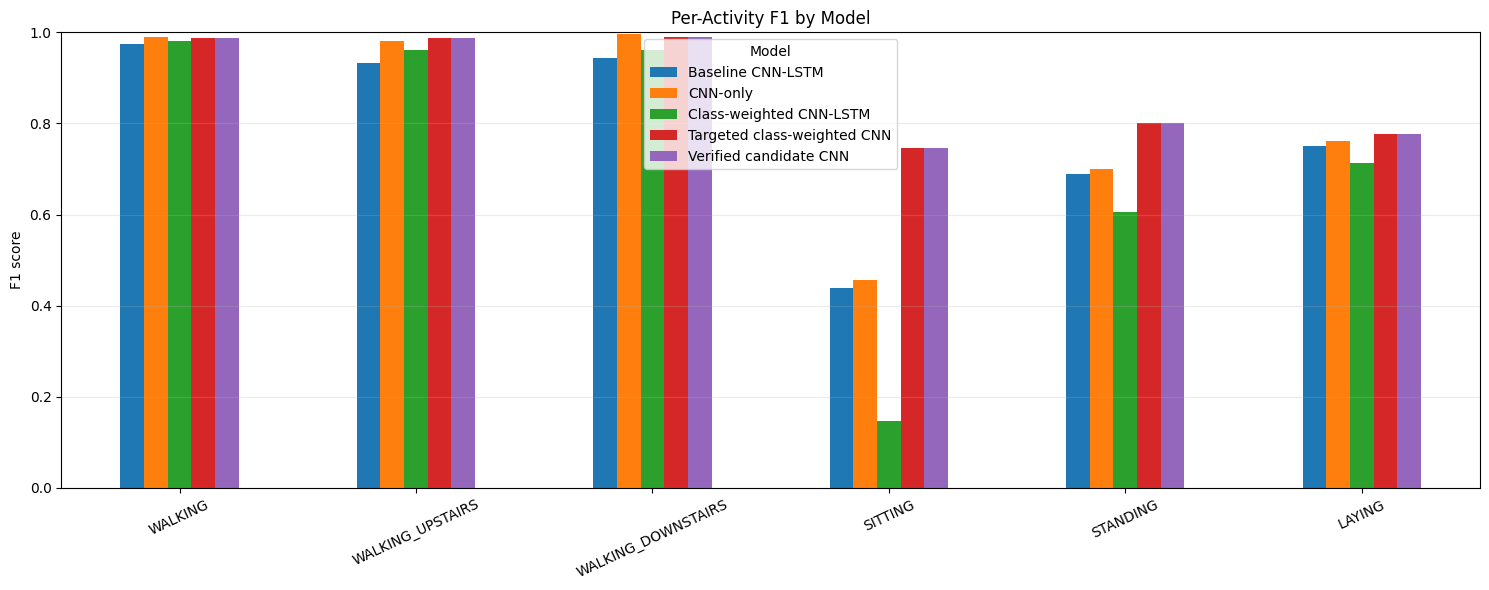

In [7]:
per_class_pivot = per_class_df.pivot(
    index="Activity", columns="Model", values="F1"
).reindex(activity_names)

display(per_class_pivot.style.format("{:.3f}"))

ax = per_class_pivot.plot(kind="bar", figsize=(15, 6), ylim=(0, 1), rot=25)
ax.set_title("Per-Activity F1 by Model")
ax.set_ylabel("F1 score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Confusion matrices for every loaded model

Rows are actual activities and columns are predicted activities.

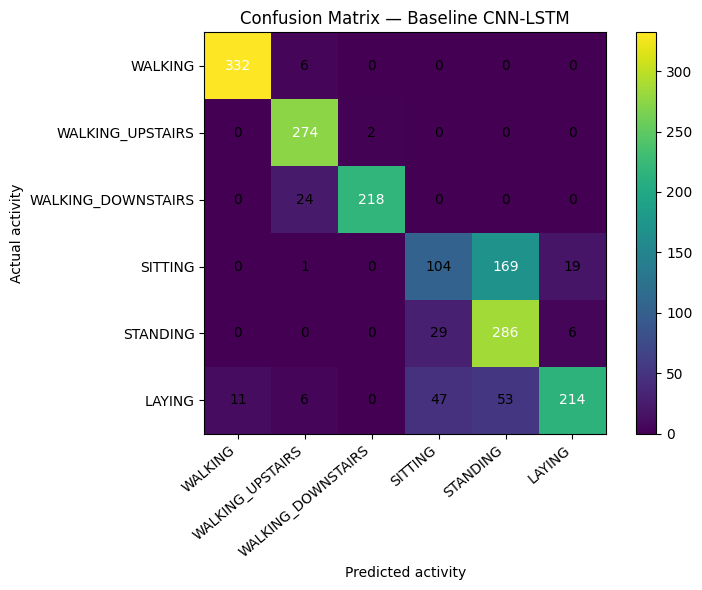

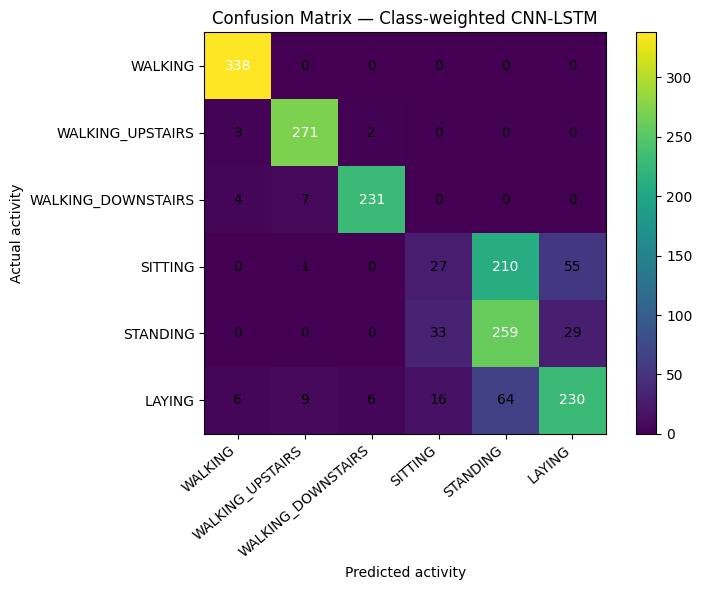

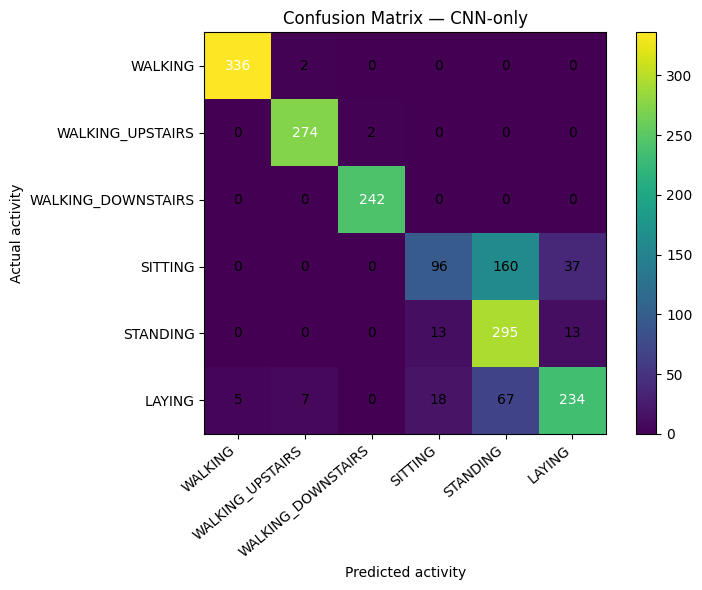

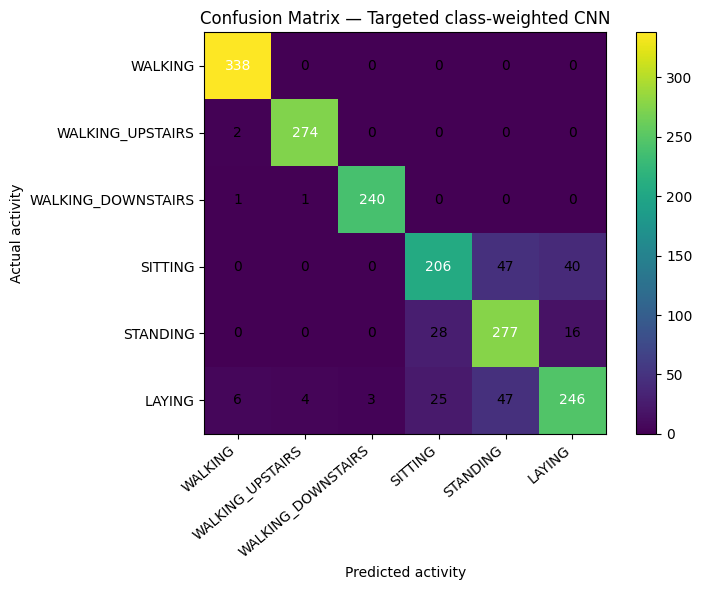

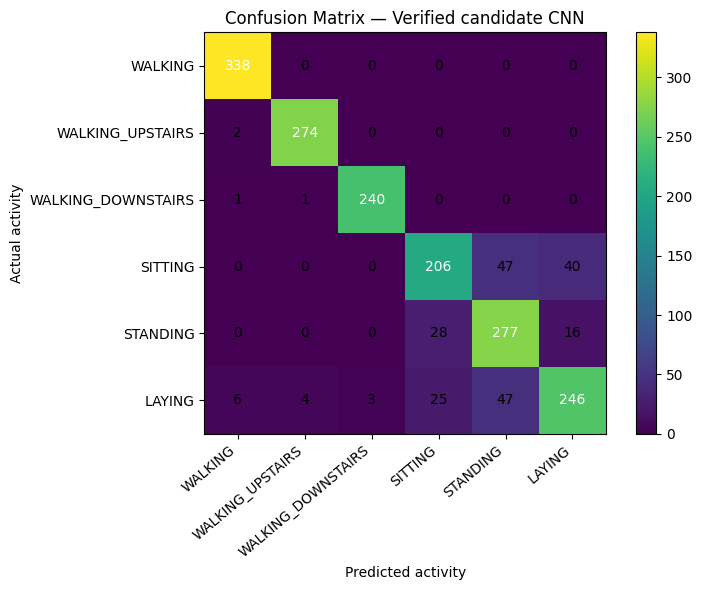

In [8]:
for model_name, preds in all_predictions.items():
    cm = confusion_matrix(
        y_val, preds, labels=np.arange(len(activity_names))
    )
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"Confusion Matrix — {model_name}")
    fig.colorbar(im, ax=ax)
    ticks = np.arange(len(activity_names))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(activity_names, rotation=40, ha="right")
    ax.set_yticklabels(activity_names)
    ax.set_xlabel("Predicted activity")
    ax.set_ylabel("Actual activity")

    threshold = cm.max() / 2 if cm.size else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black"
            )
    plt.tight_layout()
    plt.show()

## 9. Detailed classification reports

In [9]:
for model_name, report in classification_reports.items():
    print("\n" + "=" * 78)
    print(model_name)
    print("=" * 78)
    print(classification_report(
        y_val,
        all_predictions[model_name],
        labels=np.arange(len(activity_names)),
        target_names=activity_names,
        digits=4,
        zero_division=0
    ))


Baseline CNN-LSTM
                    precision    recall  f1-score   support

           WALKING     0.9679    0.9822    0.9750       338
  WALKING_UPSTAIRS     0.8810    0.9928    0.9336       276
WALKING_DOWNSTAIRS     0.9909    0.9008    0.9437       242
           SITTING     0.5778    0.3549    0.4397       293
          STANDING     0.5630    0.8910    0.6900       321
            LAYING     0.8954    0.6465    0.7509       331

          accuracy                         0.7929      1801
         macro avg     0.8127    0.7947    0.7888      1801
      weighted avg     0.8087    0.7929    0.7854      1801


Class-weighted CNN-LSTM
                    precision    recall  f1-score   support

           WALKING     0.9630    1.0000    0.9811       338
  WALKING_UPSTAIRS     0.9410    0.9819    0.9610       276
WALKING_DOWNSTAIRS     0.9665    0.9545    0.9605       242
           SITTING     0.3553    0.0922    0.1463       293
          STANDING     0.4859    0.8069    0.6066   

## 10. Check whether the targeted CNN and verified candidate are duplicates

The final candidate was previously packaged from the targeted CNN experiment. This section compares their predictions on the same validation samples. Matching predictions do not prove identical weights, but differing predictions show they are not functionally identical on this set.

In [10]:
a_name = "Targeted class-weighted CNN"
b_name = "Verified candidate CNN"

if a_name in all_predictions and b_name in all_predictions:
    a_pred = all_predictions[a_name]
    b_pred = all_predictions[b_name]
    same_prediction_fraction = float(np.mean(a_pred == b_pred))
    max_probability_difference = float(np.max(np.abs(
        all_probabilities[a_name] - all_probabilities[b_name]
    )))
    print(f"Same predicted class on validation windows: {same_prediction_fraction:.4%}")
    print(f"Maximum absolute probability difference: {max_probability_difference:.8f}")
    if np.array_equal(a_pred, b_pred) and np.allclose(
        all_probabilities[a_name], all_probabilities[b_name], atol=1e-6
    ):
        print("Result: predictions/probabilities are effectively identical on this validation set.")
    else:
        print("Result: the checkpoints differ in predictions and/or probabilities.")
else:
    print("Both checkpoints were not available; duplicate check skipped.")

Same predicted class on validation windows: 100.0000%
Maximum absolute probability difference: 0.00000000
Result: predictions/probabilities are effectively identical on this validation set.


## 11. Save the comparison artifacts to Google Drive

This saves evaluation tables and per-activity results only. It does **not** overwrite or change any model checkpoint.

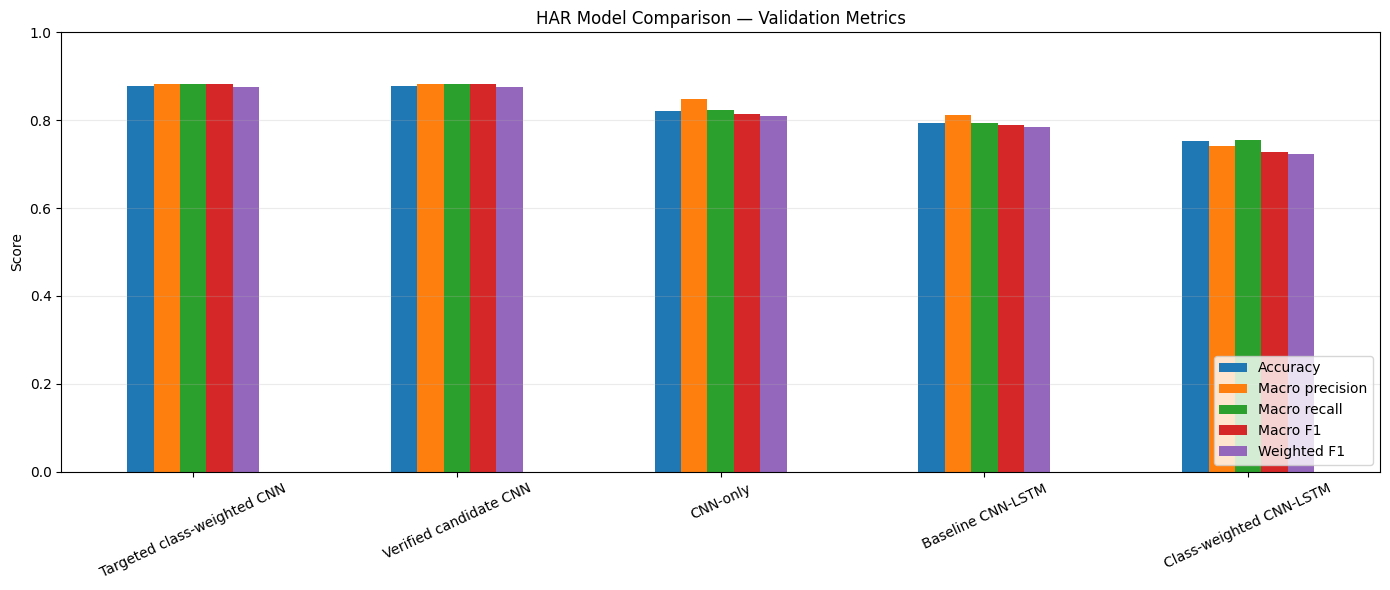

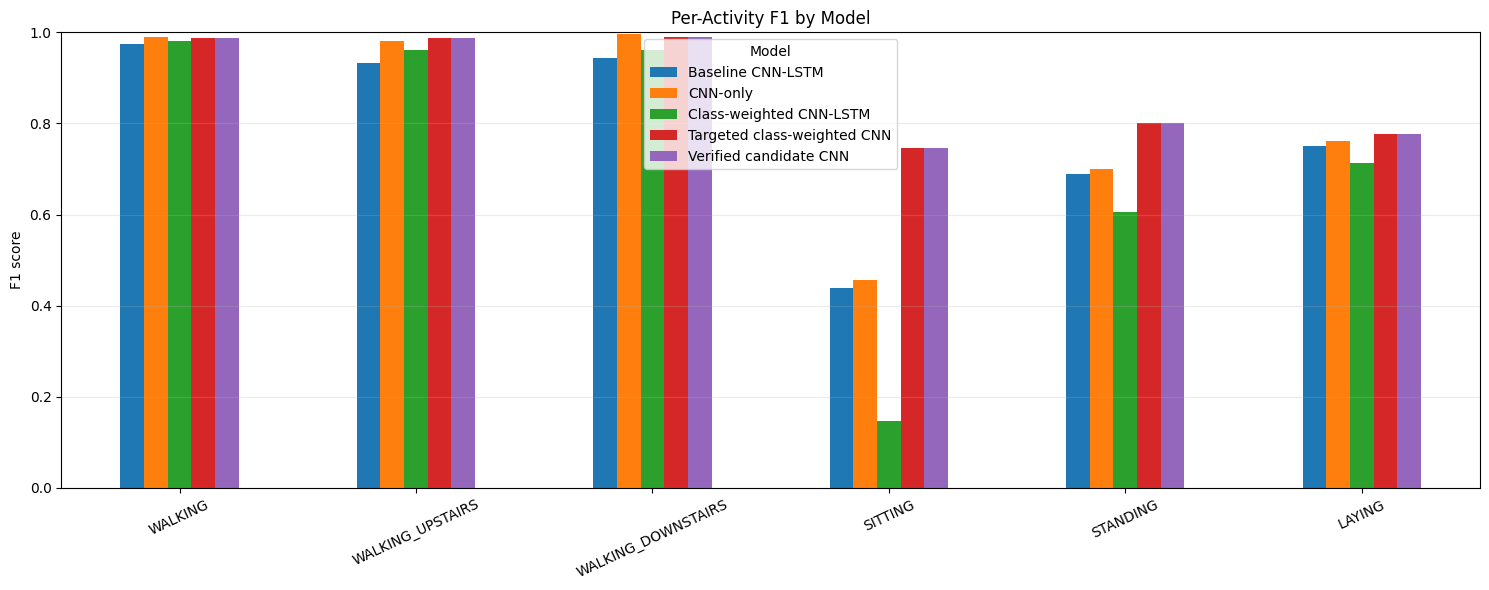

Saved comparison artifacts:
- /content/drive/MyDrive/Human_Activity_Recognition/03_Final_Model/model_comparison/validation_model_comparison.csv
- /content/drive/MyDrive/Human_Activity_Recognition/03_Final_Model/model_comparison/per_activity_model_comparison.csv
- /content/drive/MyDrive/Human_Activity_Recognition/03_Final_Model/model_comparison/checkpoint_inventory.csv
- /content/drive/MyDrive/Human_Activity_Recognition/03_Final_Model/model_comparison/classification_reports.json
- /content/drive/MyDrive/Human_Activity_Recognition/03_Final_Model/model_comparison/overall_metric_comparison.png
- /content/drive/MyDrive/Human_Activity_Recognition/03_Final_Model/model_comparison/per_activity_f1_comparison.png


In [11]:
summary_csv = OUTPUT_DIR / "validation_model_comparison.csv"
per_class_csv = OUTPUT_DIR / "per_activity_model_comparison.csv"
inventory_csv = OUTPUT_DIR / "checkpoint_inventory.csv"
reports_json = OUTPUT_DIR / "classification_reports.json"

summary_df.to_csv(summary_csv, index=False)
per_class_df.to_csv(per_class_csv, index=False)
inventory_df.to_csv(inventory_csv, index=False)

with open(reports_json, "w") as f:
    json.dump(classification_reports, f, indent=2)

# Save overall comparison plot.
ax = summary_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(14, 6), ylim=(0, 1), rot=25
)
ax.set_title("HAR Model Comparison — Validation Metrics")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "overall_metric_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Save per-activity F1 plot.
ax = per_class_pivot.plot(kind="bar", figsize=(15, 6), ylim=(0, 1), rot=25)
ax.set_title("Per-Activity F1 by Model")
ax.set_ylabel("F1 score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_activity_f1_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved comparison artifacts:")
for p in [
    summary_csv, per_class_csv, inventory_csv, reports_json,
    OUTPUT_DIR / "overall_metric_comparison.png",
    OUTPUT_DIR / "per_activity_f1_comparison.png"
]:
    print("-", p)

## 12. Final selection notes

Use the metrics above to choose a candidate, but do not automatically call the highest score the universally best model. Consider:
- Macro F1 and per-activity F1, especially for SITTING, STANDING, and LAYING.
- Whether the model checkpoint is the exact one connected to the dashboard.
- Model size and inference speed if those matter for deployment.
- The fact that this validation split has already influenced model selection.

Do not report the official test set as an untouched final evaluation if it has already been inspected during development. If you need an unbiased final estimate, agree on the model first and evaluate the official test set once in a separate final-evaluation step.